<a href="https://colab.research.google.com/github/LizaMilovanova/Labs/blob/main/%D0%9B%D0%B0%D0%B1_2_2_%D0%9C%D1%96%D0%BB%D0%BE%D0%B2%D0%B0%D0%BD%D0%BE%D0%B2%D0%B0_%D0%A4%D0%86%D0%A2_4_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [12]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("mahmoudshogaa/titanic-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'titanic-dataset' dataset.
Path to dataset files: /kaggle/input/titanic-dataset


In [13]:
df = pd.read_csv(os.path.join(path, "titanic.csv"))
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


**PassengerId**: A unique identifier for each passenger.

**Survived**: This column indicates whether a passenger survived (1) or did not survive (0).

**Pclass** (Ticket class): A proxy for socio-economic status, with 1 being the highest class and 3 the lowest.

**Name**: The name of the passenger.

**Sex**: The gender of the passenger.

**Age**: The age of the passenger. (Note: There might be missing values in this column.)

**SibSp**: The number of siblings or spouses the passenger had aboard the Titanic.

**Parch**: The number of parents or children the passenger had aboard the Titanic.

**Ticket**: The ticket number.

**Fare**: The amount of money the passenger paid for the ticket.

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [17]:
df['Age'] = df['Age'].fillna(df['Age'].median(skipna=True))

df.drop(['Cabin'], axis=1, inplace=True)
df.drop(['Embarked'], axis=1, inplace=True)

In [18]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [20]:
df = df[['Survived', 'Pclass', 'Sex', 'Age', 'Fare']]
df.head()

,Survived,Pclass,Sex,Age,Fare
0,0,3,male,22.0,7.2500
1,1,1,female,38.0,71.2833
2,1,3,female,26.0,7.9250
3,1,1,female,35.0,53.1000
4,0,3,male,35.0,8.0500


In [21]:
df['Sex'].value_counts()

,count
Sex,
male,577
female,314


In [22]:
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

print(f'Data types of the dataset:\n{df.dtypes}')

Data types of the dataset:
Survived      int64
Pclass        int64
Sex           int64
Age         float64
Fare        float64
dtype: object


In [23]:
df.describe()

,Survived,Pclass,Sex,Age,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,0.352413,29.361582,32.204208
std,0.486592,0.836071,0.477990,13.019697,49.693429
min,0.000000,1.000000,0.000000,0.420000,0.000000
25%,0.000000,2.000000,0.000000,22.000000,7.910400
50%,0.000000,3.000000,0.000000,28.000000,14.454200
75%,1.000000,3.000000,1.000000,35.000000,31.000000
max,1.000000,3.000000,1.000000,80.000000,512.329200


In [24]:
df.isnull().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,0
Fare,0


In [25]:
df.head()

,Survived,Pclass,Sex,Age,Fare
0,0,3,0,22.0,7.2500
1,1,1,1,38.0,71.2833
2,1,3,1,26.0,7.9250
3,1,1,1,35.0,53.1000
4,0,3,0,35.0,8.0500


In [26]:
df.tail()

,Survived,Pclass,Sex,Age,Fare
886,0,2,0,27.0,13.00
887,1,1,1,19.0,30.00
888,0,3,1,28.0,23.45
889,1,1,0,26.0,30.00
890,0,3,0,32.0,7.75


In [27]:
survival_by_sex = df.groupby('Sex')['Survived'].mean() * 100

print(f'Share of survived males: {survival_by_sex[0]:.2f}%')
print(f'Share of survived females: {survival_by_sex[1]:.2f}%')

Share of survived males: 18.89%
Share of survived females: 74.20%


In [28]:
print(f'Correlation between sex and survival: {df["Sex"].corr(df["Survived"])}')

Correlation between sex and survival: 0.5433513806577555


In [29]:
class1_surv_rate = df[(df['Pclass'] == 1) & (df['Survived'] == 1)].shape[0] / df[df['Pclass'] == 1].shape[0]
class2_surv_rate = df[(df['Pclass'] == 2) & (df['Survived'] == 1)].shape[0] / df[df['Pclass'] == 2].shape[0]
class3_surv_rate = df[(df['Pclass'] == 3) & (df['Survived'] == 1)].shape[0] / df[df['Pclass'] == 3].shape[0]

print(f'Share of survived class 1 passengers {class1_surv_rate * 100:.2f}%')
print(f'Share of survived class 2 passengers {class2_surv_rate * 100:.2f}%')
print(f'Share of survived class 3 passengers {class3_surv_rate * 100:.2f}%')

Share of survived class 1 passengers 62.96%
Share of survived class 2 passengers 47.28%
Share of survived class 3 passengers 24.24%


In [30]:
survived_mean_age = df[df['Survived'] == 1]['Age'].mean()
not_survived_mean_age = df[df['Survived'] == 0]['Age'].mean()

print(f'Mean age of survived passengers: {survived_mean_age:.2f}')
print(f'Mean age of not survived passengers: {not_survived_mean_age:.2f}')

Mean age of survived passengers: 28.29
Mean age of not survived passengers: 30.03


In [33]:
df['Fare_Category'] = pd.qcut(df['Fare'], 6, labels=False)

for i in range(6):
    surv_rate = df[(df['Fare_Category'] == i) & (df['Survived'] == 1)].shape[0] / df[df['Fare_Category'] == i].shape[0]
    print(f'Share of survived passengers in bucket {i}: {surv_rate * 100:.2f}%')

Share of survived passengers in bucket 0: 20.51%
Share of survived passengers in bucket 1: 19.08%
Share of survived passengers in bucket 2: 36.69%
Share of survived passengers in bucket 3: 43.62%
Share of survived passengers in bucket 4: 41.78%
Share of survived passengers in bucket 5: 69.80%


In [34]:
for i in range(1, 4):
    median_fare = df[df['Pclass'] == i]['Fare'].median()
    print(f'Median fare for class {i}: {median_fare:.2f}')

Median fare for class 1: 60.29
Median fare for class 2: 14.25
Median fare for class 3: 8.05


<Axes: xlabel='Age', ylabel='Count'>

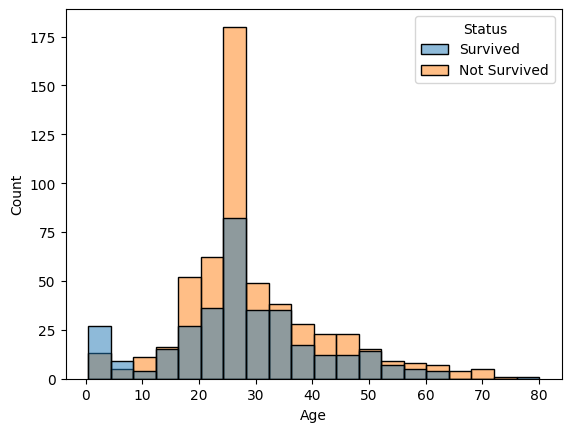

In [35]:
df_survived = df[df['Survived'] == 1][['Age']]
df_survived['Status'] = 'Survived'

df_not_survived = df[df['Survived'] == 0][['Age']]
df_not_survived['Status'] = 'Not Survived'

df_combined = pd.concat([df_survived, df_not_survived])

sns.histplot(data=df_combined, x='Age', hue='Status', bins=20)

+ Діти (до 10–15 років): мають помітно високий відсоток виживання. Це напряму підтверджує правило першочергової евакуації дітей у шлюпки.   

+ Молодь (20–30 років): найбільш численна група на борту, для якої характерні найбільші втрати — частка загиблих тут суттєво перевищує кількість тих, хто врятувався.   

+ Зрілий вік (30–50 років): загальна кількість пасажирів поступово зменшується; хоча смертність усе ще переважає, розрив між тими, хто вижив і загинув, стає менш контрастним.   

+ Старший та похилий вік (від 50 років): невелика частка від загального числа; серед найстарших пасажирів (70+) вибірка мінімальна, проте фіксуються поодинокі випадки порятунку.

In [36]:
for i in range(1, 4):
    for j in range(2):
        surv_rate = df[(df['Pclass'] == i) & (df['Sex'] == j) & (df['Survived'] == 1)].shape[0] / df[(df['Pclass'] == i) & (df['Sex'] == j)].shape[0]
        print(f'Share of survived {"male   " if j == 0 else "female"} passengers in class {i}: {surv_rate * 100:.2f}%')

Share of survived male    passengers in class 1: 36.89%
Share of survived female passengers in class 1: 96.81%
Share of survived male    passengers in class 2: 15.74%
Share of survived female passengers in class 2: 92.11%
Share of survived male    passengers in class 3: 13.54%
Share of survived female passengers in class 3: 50.00%


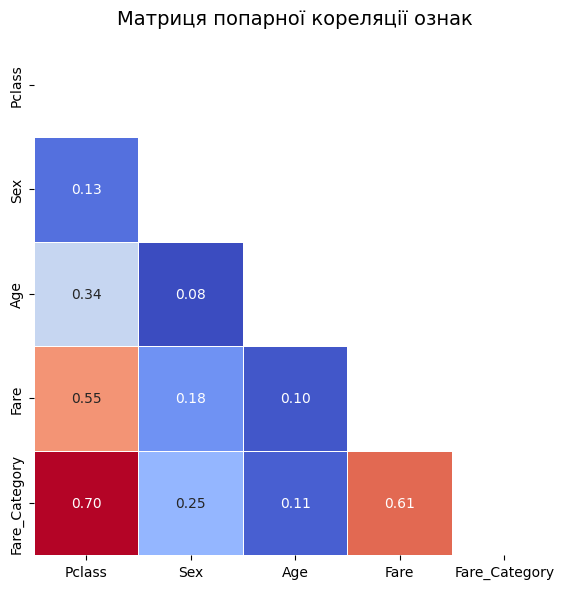

In [37]:
mtx = df.drop('Survived', axis=1).corr(numeric_only=True).abs()

fig, ax = plt.subplots(figsize=(6, 6))

sns.heatmap(
    mtx,
    cmap='coolwarm',
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    mask=np.triu(np.ones_like(mtx, dtype=bool)),
    square=True,
    cbar=False,
    ax=ax
)

plt.title("Матриця попарної кореляції ознак", fontsize=14)
plt.tight_layout()
plt.show()

In [39]:
import pandas as pd
import requests
from io import StringIO

url = "https://uk.wikipedia.org/wiki/%D0%9D%D0%B0%D1%81%D0%B5%D0%BB%D0%B5%D0%BD%D0%BD%D1%8F_%D0%A3%D0%BA%D1%80%D0%B0%D1%97%D0%BD%D0%B8#%D0%9D%D0%B0%D1%80%D0%BE%D0%B4%D0%B6%D1%83%D0%B2%D0%B0%D0%BD%D1%96%D1%81%D1%82%D1%8C$0"

headers = {
    "User-Agent": "Mozilla/5.0",
    "Accept-Language": "uk-UA,uk;q=0.9,en;q=0.8",
}

html = requests.get(url, headers=headers, timeout=30).text

df = pd.read_html(
    StringIO(html),
    match="Коефіцієнт народжуваності в регіонах України",
    thousands=".", decimal=","
)[0]

df

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,—,—
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,—
5,Житомирська,26.1,22.3,15.9,12.9,8.9,12.2,12.0,7.9
6,Закарпатська,31.4,27.3,20.7,16.8,11.5,15.1,14.6,10.4
7,Запорізька,21.9,19.7,15.0,12.4,7.1,10.6,10.6,6.8
8,Івано-Франківська,24.3,24.8,18.2,15.5,10.3,12.4,12.2,8.8
9,Київська,20.4,18.9,15.6,12.3,7.3,12.2,12.1,8.0


In [40]:
# Базовий огляд
print("Розмір датасету:", df.shape)
print("\nПерші 5 рядків:")
display(df.head())

print("\nІнформація про типи даних та пропуски:")
print(df.info())

Розмір датасету: (28, 9)

Перші 5 рядків:


,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,—,—
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,—



Інформація про типи даних та пропуски:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Регіон  28 non-null     object 
 1   1950    26 non-null     float64
 2   1960    27 non-null     float64
 3   1970    27 non-null     float64
 4   1990    28 non-null     float64
 5   2000    28 non-null     float64
 6   2012    28 non-null     float64
 7   2014    28 non-null     object 
 8   2019    28 non-null     object 
dtypes: float64(6), object(3)
memory usage: 2.1+ KB
None


In [41]:
# Перевіряємо назви стовпців
df.columns = [str(col).strip() for col in df.columns]
region_col = df.columns[0]

# Вилучаємо загальнонаціональний рядок для аналізу виключно по областях
df_regions = df[~df[region_col].str.contains('Україна|Всього', case=False, na=False)].copy()

# Перетворюємо всі колонки років у числовий формат
year_cols = df.columns[1:]
for col in year_cols:
    df_regions[col] = pd.to_numeric(df_regions[col].astype(str).str.replace('—', '').str.replace('-', ''), errors='coerce')

In [42]:
# Підрахунок пропусків
print("Кількість пропусків по стовпцях:")
print(df_regions[year_cols].isnull().sum())

# Заповнення пропусків медіаною по відповідному року
for col in year_cols:
    df_regions[col] = df_regions[col].fillna(df_regions[col].median(skipna=True))

print("\nПеревірка після заповнення (залишок NaN):", df_regions[year_cols].isnull().sum().sum())

Кількість пропусків по стовпцях:
1950    2
1960    1
1970    1
1990    0
2000    0
2012    0
2014    2
2019    4
dtype: int64

Перевірка після заповнення (залишок NaN): 0


In [43]:
stats = df_regions[year_cols].describe().T[['mean', 'std', 'min', '50%', 'max']]
stats.rename(columns={'50%': 'median'}, inplace=True)
print("Описова статистика коефіцієнта народжуваності за роками:")
display(stats)

Описова статистика коефіцієнта народжуваності за роками:


,mean,std,min,median,max
1950,23.051852,2.772998,18.6,22.4,31.4
1960,20.733333,2.938341,16.3,20.1,27.3
1970,15.588889,1.869663,12.7,15.3,20.7
1990,13.059259,1.554462,10.8,12.6,16.8
2000,8.222222,1.584379,6.1,7.9,11.8
2012,11.655556,1.666718,9.4,11.5,15.9
2014,11.148148,1.972576,5.1,11.2,14.8
2019,8.000000,1.364664,6.0,7.9,11.0


In [44]:
latest_year = year_cols[-1]

top_regions = df_regions.sort_values(by=latest_year, ascending=False)[[region_col, latest_year]].head(5)
bottom_regions = df_regions.sort_values(by=latest_year, ascending=True)[[region_col, latest_year]].head(5)

print(f"Топ-5 регіонів за народжуваністю у {latest_year} році:")
display(top_regions)

print(f"\nРегіони з найнижчим коефіцієнтом у {latest_year} році:")
display(bottom_regions)

Топ-5 регіонів за народжуваністю у 2019 році:


,Регіон,2019
25,Київ,11.0
16,Рівненська,10.7
6,Закарпатська,10.4
2,Волинська,10.1
23,Чернівецька,9.2



Регіони з найнижчим коефіцієнтом у 2019 році:


,Регіон,2019
17,Сумська,6.0
24,Чернігівська,6.1
22,Черкаська,6.4
15,Полтавська,6.5
19,Харківська,6.8


In [45]:
df_regions['Birth_Rate_Level'] = pd.qcut(
    df_regions[latest_year],
    q=3,
    labels=['Низький', 'Середній', 'Високий']
)

print(f"Розподіл регіонів за категоріями у {latest_year} році:")
print(df_regions['Birth_Rate_Level'].value_counts())

Розподіл регіонів за категоріями у 2019 році:
Birth_Rate_Level
Низький     9
Середній    9
Високий     9
Name: count, dtype: int64


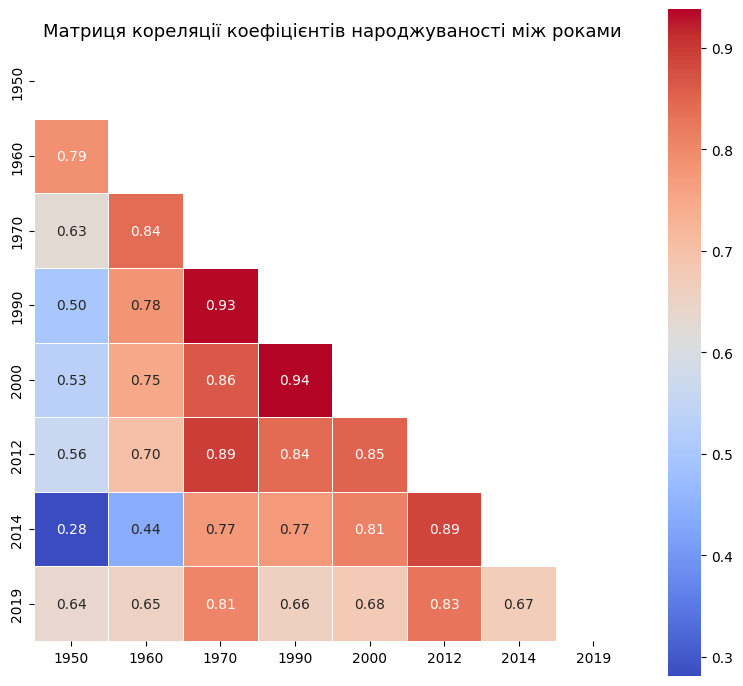

In [46]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Матриця попарної кореляції
mtx_corr = df_regions[year_cols].corr().abs()

fig, ax = plt.subplots(figsize=(8, 7))

sns.heatmap(
    mtx_corr,
    cmap='coolwarm',
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    mask=np.triu(np.ones_like(mtx_corr, dtype=bool)), # маскуємо верхній трикутник
    square=True,
    cbar=True,
    ax=ax
)

plt.title("Матриця кореляції коефіцієнтів народжуваності між роками", fontsize=13)
plt.tight_layout()
plt.show()

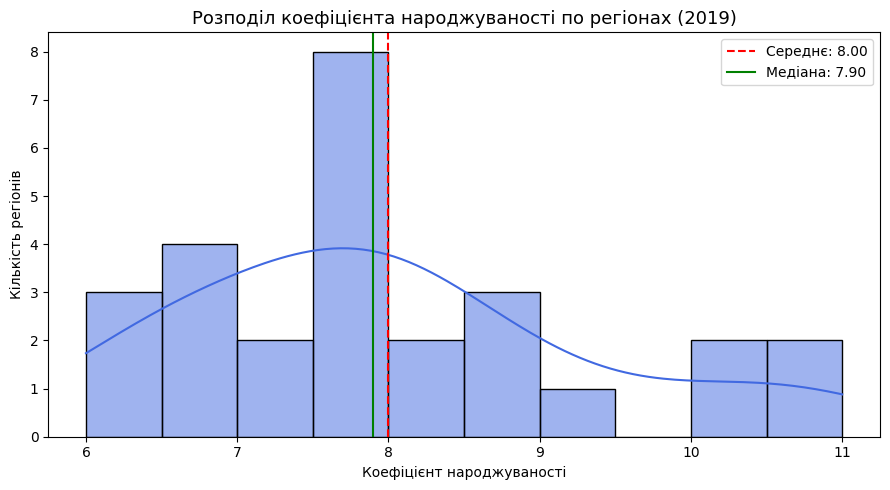

In [47]:
plt.figure(figsize=(9, 5))
sns.histplot(df_regions[latest_year], kde=True, bins=10, color='royalblue')

mean_val = df_regions[latest_year].mean()
median_val = df_regions[latest_year].median()

plt.axvline(mean_val, color='red', linestyle='--', label=f'Середнє: {mean_val:.2f}')
plt.axvline(median_val, color='green', linestyle='-', label=f'Медіана: {median_val:.2f}')

plt.title(f"Розподіл коефіцієнта народжуваності по регіонах ({latest_year})", fontsize=13)
plt.xlabel("Коефіцієнт народжуваності")
plt.ylabel("Кількість регіонів")
plt.legend()
plt.tight_layout()
plt.show()

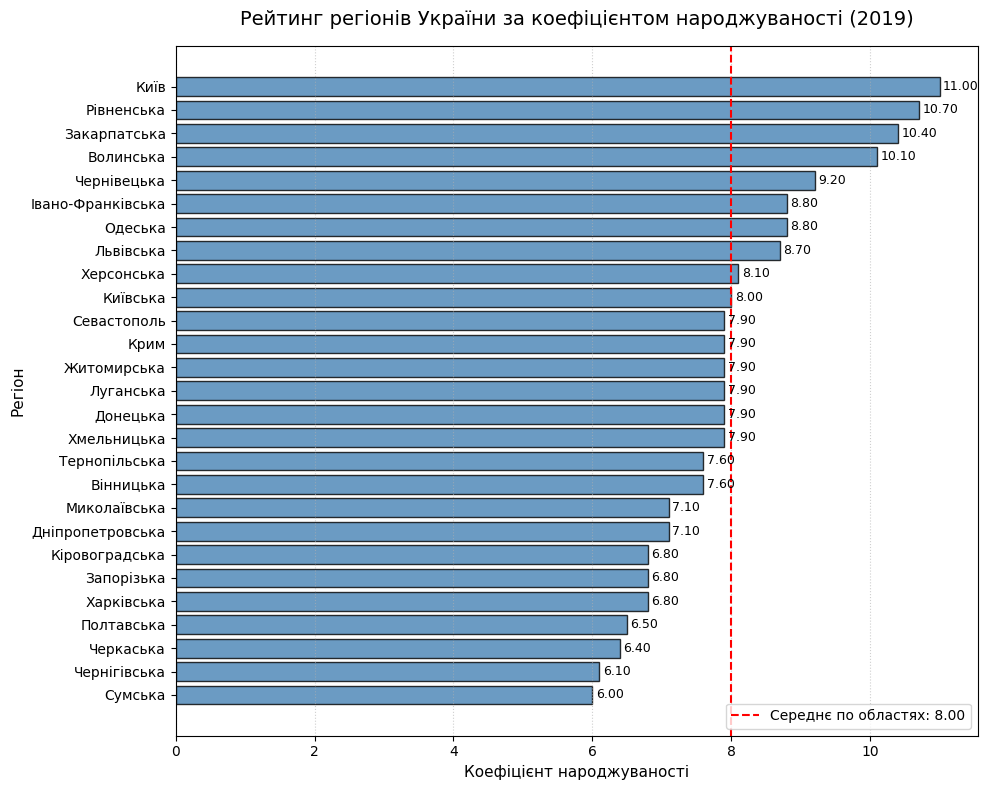

In [48]:
# Сортуємо області за спаданням показника за останній рік
df_sorted = df_regions.sort_values(by=latest_year, ascending=True)

plt.figure(figsize=(10, 8))

# Побудова стовпчастої діаграми
bars = plt.barh(
    df_sorted[region_col],
    df_sorted[latest_year],
    color='steelblue',
    edgecolor='black',
    alpha=0.8
)

# Додаємо вертикальну лінію середнього значення
avg_val = df_regions[latest_year].mean()
plt.axvline(
    avg_val,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label=f'Середнє по областях: {avg_val:.2f}'
)

# Підписи значень біля кожного стовпчика
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.05,
        bar.get_y() + bar.get_height() / 2,
        f'{width:.2f}',
        va='center',
        fontsize=9
    )

plt.title(f'Рейтинг регіонів України за коефіцієнтом народжуваності ({latest_year})', fontsize=14, pad=15)
plt.xlabel('Коефіцієнт народжуваності', fontsize=11)
plt.ylabel('Регіон', fontsize=11)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()